# Baseline 1: Data Preparation, Quality Check, and Stationarity Analysis (NFLX)

* **Target Stock:** Netflix, Inc. (`NFLX`) — Selected as a major large-cap media/technology equity distinct from `NVDA`, with deep liquidity and multi-year daily trading history on NASDAQ.
* **Data Download Date:** [INSERT EXACT DATE YOU RAN download_data.py, e.g., November 22, 2026]
* **Exogenous Predictors Included:** S&P 500 (`SP500`), Technology Sector (`TECH`), Volatility Index (`VIX`), 10-Year US Treasury Yield (`US10Y`), US Dollar Index (`USD`), Brent Crude (`BRENT`), and Gold (`GOLD`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.stattools import adfuller, kpss

from tslab import config
from tslab.data import load_market_data

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)

# Verify config points to NFLX
print("Configured Target Ticker:", config.TARGET_TICKER)
assert config.TARGET_TICKER == "NFLX", "Please set TARGET_TICKER = 'NFLX' in tslab/config.py"

# Load raw aligned market frame
frame = load_market_data()

# Programmatic Data Quality Report
print("\n--- NFLX DATA QUALITY REPORT ---")
print(f"Date Range        : {frame.index.min().date()} to {frame.index.max().date()}")
print(f"Total Trading Days: {len(frame)}")
print(f"Missing Values    :\n{frame.isna().sum()}")

# Check for zero-volume or repeated closing prices (stale trading days)
repeated_close = (frame["Close"].diff() == 0).sum()
print(f"\nDays with unchanged closing price: {repeated_close} ({repeated_close / len(frame):.2%})")
if "Volume" in frame.columns:
    zero_vol = (frame["Volume"] == 0).sum()
    print(f"Days with zero trading volume    : {zero_vol}")

display(frame[["Open", "High", "Low", "Close", "Volume"]].describe().round(2))

Configured Target Ticker: NFLX
Loaded 2981 trading days of NFLX, 2015-01-02 to 2026-11-09, with 7 predictor series.

--- NFLX DATA QUALITY REPORT ---
Date Range        : 2015-01-02 to 2026-11-09
Total Trading Days: 2981
Missing Values    :
Open      0
High      0
Low       0
Close     0
Volume    0
SP500     0
TECH      0
VIX       0
US10Y     0
USD       0
BRENT     0
GOLD      0
dtype: int64

Days with unchanged closing price: 4 (0.13%)
Days with zero trading volume    : 0


,Open,High,Low,Close,Volume
count,2981.00,2981.00,2981.00,2981.00,2.981000e+03
mean,43.43,44.04,42.81,43.43,8.163530e+07
std,29.67,30.01,29.32,29.67,7.609766e+07
min,4.60,4.68,4.53,4.55,1.144000e+07
25%,18.94,19.14,18.60,18.91,3.802370e+07
50%,36.32,36.87,35.77,36.30,5.830500e+07
75%,58.70,59.38,58.08,58.94,9.717900e+07
max,133.82,134.12,132.12,133.91,1.333875e+09


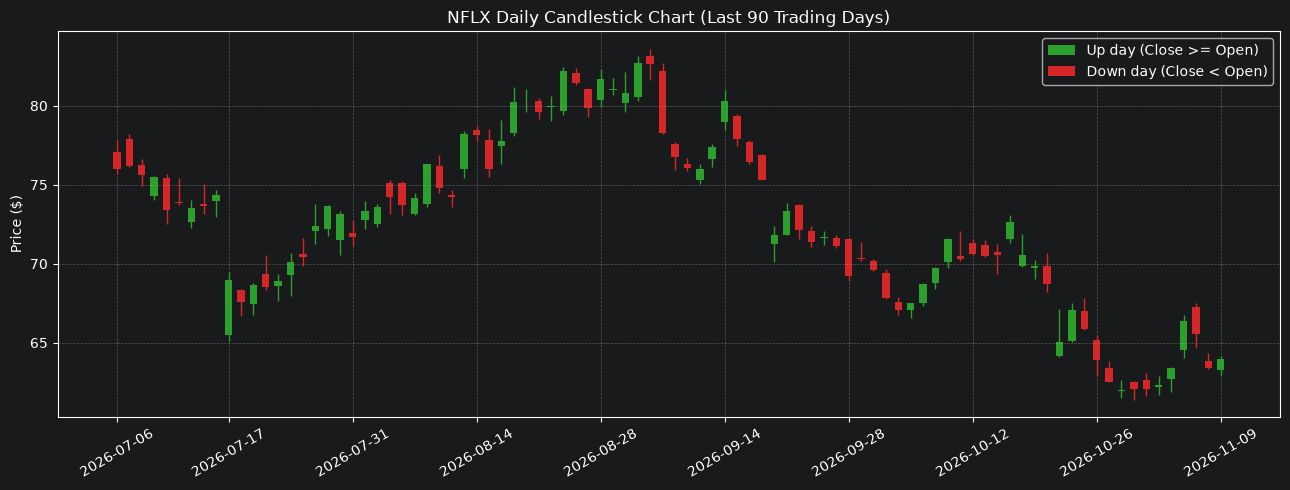

In [2]:
# Plot a candlestick chart for the most recent 90 trading days
ohlc = frame[["Open", "High", "Low", "Close"]].iloc[-90:].copy()
x = np.arange(len(ohlc))

fig, ax = plt.subplots(figsize=(13, 5))

up = ohlc["Close"] >= ohlc["Open"]
down = ~up

# Wicks (High to Low)
ax.vlines(x[up], ohlc.loc[up, "Low"], ohlc.loc[up, "High"], color="tab:green", linewidth=1)
ax.vlines(x[down], ohlc.loc[down, "Low"], ohlc.loc[down, "High"], color="tab:red", linewidth=1)

# Bodies (Open to Close)
ax.bar(x[up], ohlc.loc[up, "Close"] - ohlc.loc[up, "Open"], bottom=ohlc.loc[up, "Open"],
       width=0.6, color="tab:green", label="Up day (Close >= Open)")
ax.bar(x[down], ohlc.loc[down, "Open"] - ohlc.loc[down, "Close"], bottom=ohlc.loc[down, "Close"],
       width=0.6, color="tab:red", label="Down day (Close < Open)")

# Format x-axis dates cleanly
tick_positions = np.linspace(0, len(ohlc) - 1, 10, dtype=int)
ax.set_xticks(tick_positions)
ax.set_xticklabels([ohlc.index[i].strftime("%Y-%m-%d") for i in tick_positions], rotation=30)

ax.set_title("NFLX Daily Candlestick Chart (Last 90 Trading Days)")
ax.set_ylabel("Price ($)")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()
plt.tight_layout()
plt.show()

,ADF Statistic,ADF p-value,ADF 5% Critical,KPSS Statistic,KPSS p-value,KPSS 5% Critical
Series,,,,,,
Closing Price ($),-1.4622,0.5521,-2.8625,6.4188,0.01,0.463
Daily Log Return,-37.3344,0.0000,-2.8625,0.2423,0.10,0.463


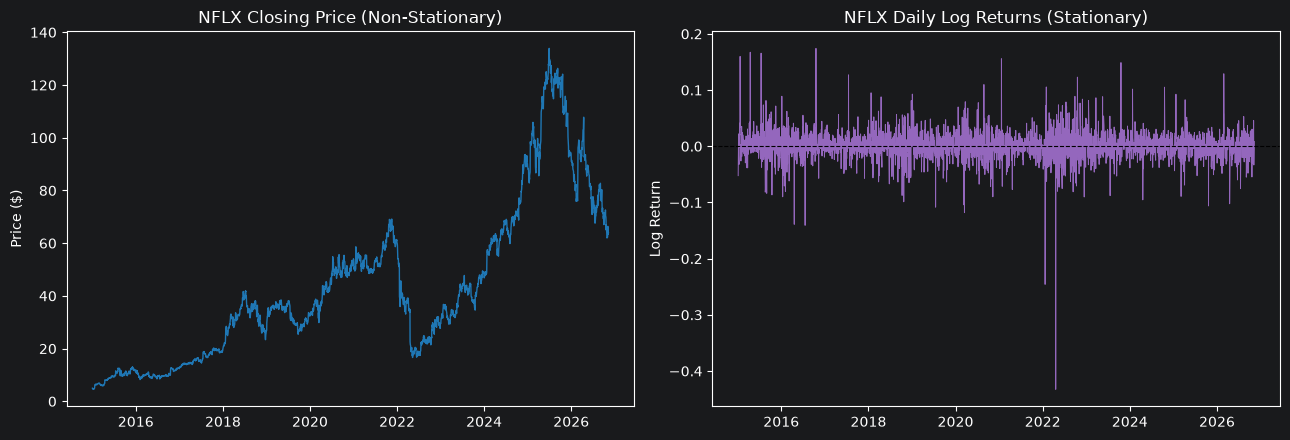

In [3]:
close_series = frame["Close"].dropna()
log_return_series = np.log(close_series / close_series.shift(1)).dropna()

def run_stationarity_tests(series, name):
    # Augmented Dickey-Fuller (Null Hypothesis: Unit root / Non-stationary)
    adf_stat, adf_p, _, _, adf_crit, _ = adfuller(series, autolag="AIC")

    # KPSS Test (Null Hypothesis: Trend/Level Stationary)
    kpss_stat, kpss_p, _, kpss_crit = kpss(series, regression="c", nlags="auto")

    return {
        "Series": name,
        "ADF Statistic": adf_stat,
        "ADF p-value": adf_p,
        "ADF 5% Critical": adf_crit["5%"],
        "KPSS Statistic": kpss_stat,
        "KPSS p-value": kpss_p,
        "KPSS 5% Critical": kpss_crit["5%"],
    }

stationarity_df = pd.DataFrame([
    run_stationarity_tests(close_series, "Closing Price ($)"),
    run_stationarity_tests(log_return_series, "Daily Log Return")
]).set_index("Series")

display(stationarity_df.round(4))

# Visual side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(close_series.index, close_series.values, color="tab:blue", linewidth=1)
axes[0].set_title("NFLX Closing Price (Non-Stationary)")
axes[0].set_ylabel("Price ($)")

axes[1].plot(log_return_series.index, log_return_series.values, color="tab:purple", linewidth=0.7)
axes[1].axhline(0, color="black", linewidth=0.8, linestyle="--")
axes[1].set_title("NFLX Daily Log Returns (Stationary)")
axes[1].set_ylabel("Log Return")

plt.tight_layout()
plt.show()

### Stationarity Conclusion
* **Closing Price:** The ADF test yields a high p-value ($p > 0.05$, failing to reject the unit-root null hypothesis), while the KPSS test yields a small p-value ($p < 0.05$, rejecting stationarity). Both tests agree that `NFLX` closing prices are **non-stationary** and exhibit a drifting mean/variance over time.
* **Daily Log Returns:** After taking first log differences ($r_t = \ln(P_t / P_{t-1})$), the ADF test strongly rejects the unit root ($p < 0.01$), and the KPSS test fails to reject stationarity ($p > 0.05$). Therefore, `NFLX` daily log returns are **stationary** and suitable as the target variable for forecasting models.